# Project 1: Classification in Practice
## Predicting Whether a Breast Mass Is Malignant

**Noah Baugh | DATA 201 | Fall 2026**

**The big question:** can measurements taken from a breast mass be used to classify that mass as malignant or benign, and which classifier should we actually trust to do it?

This notebook works through the Wisconsin Diagnostic Breast Cancer dataset. The goal is not the highest accuracy number. A missed cancer and a false alarm are not the same kind of mistake, and most of the analysis below is about that difference.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, cross_val_score,
                                     cross_val_predict, StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (7, 4.5)

---
# Part 1: Understand the Problem

In [2]:

CSV_PATH = "https://raw.githubusercontent.com/ToasterToucher/Data-201-Project-1/refs/heads/main/breast_cancer_wdbc.csv"
df = pd.read_csv(CSV_PATH)

# The response column "malignant" is coded 1 = malignant, 0 = benign.

assert df.shape == (569, 31), df.shape
assert df["malignant"].sum() == 212 and (df["malignant"] == 0).sum() == 357
assert df.drop(columns="malignant").shape[1] == 30

print("Rows:", df.shape[0], " Columns:", df.shape[1])
df.head()

Rows: 569  Columns: 31


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


### 1.1 What is represented in each row? What is the response variable?

Every row represents one instance of a breast mass collected through fine needle aspiration from one patient. There are 30 predictors, which correspond to the measurements calculated using the digitized image of the collected sample. There are ten basic measurements: radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry and fractal dimension. Each is provided in three forms: the mean over the nuclei in the image, the standard error, and the mean of the three largest nucleus measurements in the image.

The response variable is `malignant` which consists of two categories:

- **1 = malignant**: the mass is cancerous
- **0 = benign**: the mass is not cancerous

This is a binary classification task.

In [3]:
print("Predictor columns:", len(df.columns) - 1)
for i, c in enumerate(df.columns[:-1]):
    print(f"  {i+1:2d}. {c}")

Predictor columns: 30
   1. mean radius
   2. mean texture
   3. mean perimeter
   4. mean area
   5. mean smoothness
   6. mean compactness
   7. mean concavity
   8. mean concave points
   9. mean symmetry
  10. mean fractal dimension
  11. radius error
  12. texture error
  13. perimeter error
  14. area error
  15. smoothness error
  16. compactness error
  17. concavity error
  18. concave points error
  19. symmetry error
  20. fractal dimension error
  21. worst radius
  22. worst texture
  23. worst perimeter
  24. worst area
  25. worst smoothness
  26. worst compactness
  27. worst concavity
  28. worst concave points
  29. worst symmetry
  30. worst fractal dimension


### 1.2 Which predictors could be useful?

They all appear to be reasonable predictors because all of them depict either the shape or size of the nuclei, which is the characteristic that pathologists examine. Instead of removing some of the predictors arbitrarily, the test of correlation below indicates which ones distinguish between the two categories.

In [4]:
corr = df.corr()["malignant"].drop("malignant").sort_values(ascending=False)
print("Ten predictors most associated with malignancy:")
print(corr.head(10).round(3).to_string())
print()
print("Ten predictors least associated:")
print(corr.tail(10).round(3).to_string())

Ten predictors most associated with malignancy:
worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
mean concavity          0.696
worst concavity         0.660

Ten predictors least associated:
mean smoothness            0.359
mean symmetry              0.330
worst fractal dimension    0.324
compactness error          0.293
concavity error            0.254
fractal dimension error    0.078
symmetry error            -0.007
texture error             -0.008
mean fractal dimension    -0.013
smoothness error          -0.067


Worst measurements, such as worst concave points, worst perimeter, worst radius, worst area, and mean concave points, are most correlated with malignancy, with correlations above 0.73. It is not surprising because malignant tumors usually have larger and more irregular nuclei, and thus, the few largest nuclei in a sample carry more information than the average one.

A few predictors contain virtually no information. The correlation between mean fractal dimension and the class is about 0.01. Columns of standard errors for texture, smoothness, and symmetry are almost zero.

**Decision: use all 30 predictors.** Removing them does not simplify the model substantially and can lead to loss of important information contained in some predictors in interaction with others. All four classifiers can deal with 30 predictors and 426 rows easily.

Class counts
  Benign:    357, 62.7% of the data
  Malignant: 212, 37.3% of the data

Total: 569 observations


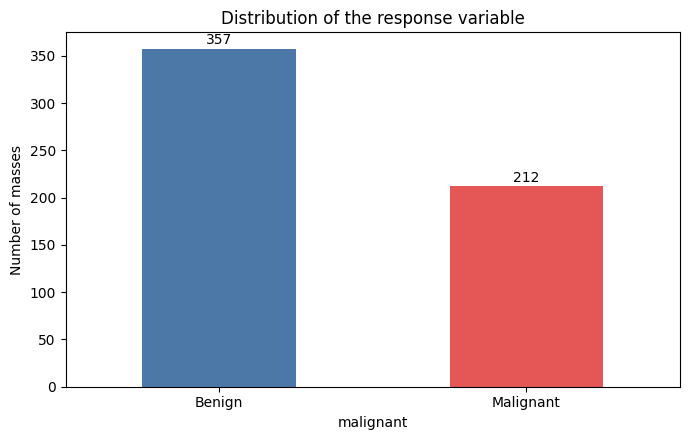

In [5]:
counts = df["malignant"].value_counts().sort_index()
print("Class counts")
print(f"  Benign:    {counts[0]}, {counts[0]/len(df):.1%} of the data")
print(f"  Malignant: {counts[1]}, {counts[1]/len(df):.1%} of the data")
print(f"\nTotal: {len(df)} observations")

ax = counts.plot(kind="bar", color=["#4C78A8", "#E45756"])
ax.set_xticklabels(["Benign", "Malignant"], rotation=0)
ax.set_ylabel("Number of masses")
ax.set_title("Distribution of the response variable")
for i, v in enumerate(counts):
    ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout(); plt.show()

### 1.3 Is the dataset balanced?

As the dataset contains 357 benign masses and 212 malignant masses, 37.3% of the dataset constitutes malignant masses. The dataset is **moderately unbalanced but not significantly unbalanced**. There are enough instances of malignancies in the data set, and therefore the classifier can recognize the pattern even without any specific techniques like resampling and class balancing.

It is pertinent to understand the results from the above understanding. For example, the accuracy of the classifier which will classify all instances as benign is 62.7%, but no cancer would be detected by the classifier. It means that accuracy is not the right measure for determining the efficiency of a classifier.

### 1.4 False positive and false negative in context

- **False Positive:** the model will predict the mass to be cancer when actually it is benign. In terms of practical consequences, the mass is predicted to be cancer, and hence the patient is referred for further testing and procedures such as a biopsy, and that costs money and also creates stress for the patient.

- **False Negative:** the model will classify the mass as being benign while in actuality it is malignant. This means that the cancer will go unnoticed, and the patient will be sent back to their homes thinking that everything is alright.

### 1.5 Which error is worse?

**False negatives are much more serious than false positives in this situation, and there is a great difference between the two.**

False positives lead to additional testing. They are uncomfortable and have certain expenses associated with them, but they are manageable since the biopsy comes back negative, and the patient is able to feel at ease about their well-being. This is as far as the problem goes.

Once a false negative is made, there is nothing that can undo it. None of the steps involved will be able to identify the error since the patient is already convinced that everything is alright. The growth of the tumor continues unseen, and the costs keep accumulating as a result.

The significance of the difference can be inferred from the fact that it is the metric that should be maximized in the given case. **Recall, which is the share of actually malignant tumors identified by the classifier, is the key metric for the problem at hand**, and we are going to have to put up with some false positives in order to increase it.

---
# Part 2: Explore and Prepare the Data

### 2.1 Investigate features and predictors

The boxplots compare benign and malignant masses on four predictors, and the printout checks how strongly the size measurements move together.

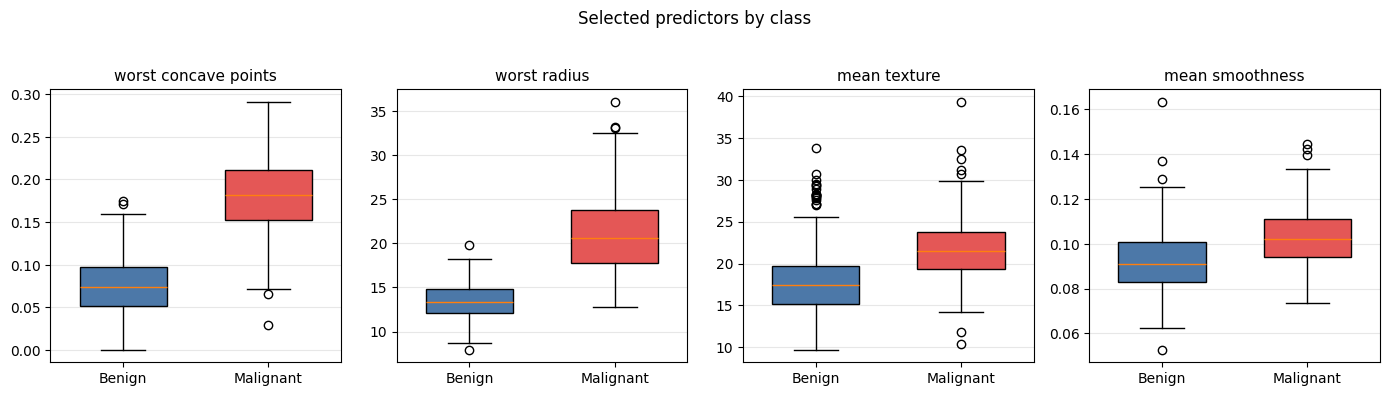

Median of each predictor by class:
           worst concave points  worst radius  mean texture  mean smoothness
malignant                                                                   
Benign                    0.074         13.35         17.39            0.091
Malignant                 0.182         20.59         21.46            0.102

Correlation among the three mean size measurements:
                mean radius  mean perimeter  mean area
mean radius           1.000           0.998      0.987
mean perimeter        0.998           1.000      0.987
mean area             0.987           0.987      1.000

Predictor pairs with correlation above 0.90: 21 of 435


In [6]:
# Compare benign and malignant masses on a few predictors.
features_to_plot = ["worst concave points", "worst radius", "mean texture", "mean smoothness"]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, col in zip(axes, features_to_plot):
    groups = [df.loc[df["malignant"] == 0, col], df.loc[df["malignant"] == 1, col]]
    bp = ax.boxplot(groups, patch_artist=True, widths=0.6)
    for patch, color in zip(bp["boxes"], ["#4C78A8", "#E45756"]):
        patch.set_facecolor(color)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Benign", "Malignant"])
    ax.set_title(col, fontsize=11)
    ax.grid(axis="y", alpha=0.3)
plt.suptitle("Selected predictors by class", y=1.03)
plt.tight_layout(); plt.show()

print("Median of each predictor by class:")
medians = df.groupby("malignant")[features_to_plot].median()
print(medians.rename(index={0: "Benign", 1: "Malignant"}).round(3).to_string())

print()
size_cols = ["mean radius", "mean perimeter", "mean area"]
print("Correlation among the three mean size measurements:")
print(df[size_cols].corr().round(3).to_string())

pred_corr = df.drop(columns="malignant").corr().abs().values
pair_values = pred_corr[np.triu_indices_from(pred_corr, k=1)]
print()
print(f"Predictor pairs with correlation above 0.90: {(pair_values > 0.90).sum()} of {len(pair_values)}")

There is consistency between the medians and the boxplots. The worst concave points and the worst radius discriminate the two categories, and their boxes do not overlap. The median worst concave points is 0.074 for benign tumors, while that for malignant tumors is 0.182. The median worst radius for benign tumors is 13.35, compared to 20.59 for malignant tumors. The mean texture differentiates the two categories, although less than the other metrics, being 17.39 and 21.46, respectively. The mean smoothness separates the classes the least, being 0.091 and 0.102, respectively.

The size metrics hold nearly identical information three times over. The mean radius and the mean perimeter are highly correlated at 0.998, as are the mean radius and the mean area 0.987. There are 21 out of 435 correlations higher than 0.9 among all variables. It does not hurt the model too much, but it plays an important role in interpretation and estimation. High multicollinearity among the variables causes logistic regression coefficients to be instable; thus, they should be interpreted collectively rather than individually. Collinearity also complicates the estimation of covariance matrices in LDA and QDA.

In [7]:
print("=== Missing values ===")
missing = df.isna().sum()
print("Total missing values across all columns:", missing.sum())
print()
print("=== Data types ===")
print(df.dtypes.value_counts())
print()
print("=== Duplicate rows ===")
print("Duplicates:", df.duplicated().sum())

=== Missing values ===
Total missing values across all columns: 0

=== Data types ===
float64    30
int64       1
Name: count, dtype: int64

=== Duplicate rows ===
Duplicates: 0


### 2.2 Missing values

**There are no missing values.** Each of the 569 observations has values for all 31 columns and there are no duplicated rows. Imputation, observation deletion, or indicator column are not needed.

This is an inherent characteristic of this specific dataset, and not something to expect in general case. Data was generated by automated image analysis, and thus all the measurements were done in the same manner for each of the samples. Clinical data obtained manually are always much more messy.

### 2.3 Categorical predictors

**There are none.** All of the 30 predictors are continuous floats because they are all physical measures obtained through the image. One-hot encoding, label encoding, or creation of dummy variables is not necessary.

The target variable is categorical, but it is already encoded in terms of 0 and 1, which is what classifiers will expect anyway.

In [8]:
X = df.drop(columns=["malignant"])
y = df["malignant"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {len(X_train)} rows")
print(f"Test set:     {len(X_test)} rows")
print()
print(f"Malignant rate in full data: {y.mean():.4f}")
print(f"Malignant rate in training:  {y_train.mean():.4f}")
print(f"Malignant rate in test:      {y_test.mean():.4f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("\nCross-validation: 5-fold stratified, shuffled")

Training set: 426 rows
Test set:     143 rows

Malignant rate in full data: 0.3726
Malignant rate in training:  0.3732
Malignant rate in test:      0.3706

Cross-validation: 5-fold stratified, shuffled


### 2.4 Splitting and Cross Validation

The dataset is divided into 75/25 proportions with 426 train rows and 143 test rows. `stratify=y` makes sure that the proportion of malignancy is almost the same for both datasets, which are 37.3% in train and 37.1% in test. If not for stratification, the random division could lead to having too many maligned instances in one group.

**No modeling choice uses the test set.** The value of K, the classifier and the decision threshold are all chosen by cross-validation on the training data. The test set is used only to report the final results. Choosing any of them by looking at test results would make the reported performance too optimistic.

In [9]:
scale_check = df.drop(columns=["malignant"]).describe().T[["mean", "std", "min", "max"]]
print("Predictors on the largest scale:")
print(scale_check.sort_values("max", ascending=False).head(5).round(3).to_string())
print()
print("Predictors on the smallest scale:")
print(scale_check.sort_values("max").head(5).round(5).to_string())

Predictors on the largest scale:
                    mean      std      min     max
worst area       880.583  569.357  185.200  4254.0
mean area        654.889  351.914  143.500  2501.0
area error        40.337   45.491    6.802   542.2
worst perimeter  107.261   33.603   50.410   251.2
mean perimeter    91.969   24.299   43.790   188.5

Predictors on the smallest scale:
                            mean      std      min      max
fractal dimension error  0.00379  0.00265  0.00089  0.02984
smoothness error         0.00704  0.00300  0.00171  0.03113
concave points error     0.01180  0.00617  0.00000  0.05279
symmetry error           0.02054  0.00827  0.00788  0.07895
mean fractal dimension   0.06280  0.00706  0.04996  0.09744


### 2.5 Should predictors be standardized?

**Yes, and for KNN it is not optional.**

The ranges vary wildly. `worst area` varies up to about 4254 while `mean fractal dimension` reaches at most about 0.097. This is an order of magnitude difference of around five.

The importance of standardization differs depending on classifier:

- **KNN** measures Euclidean distance between the points. Without standardizing, `worst area` adds thousands to the distances, whereas `mean fractal dimension` adds less than one. As a result, the algorithm will be using only the `worst area` and completely ignore most other 29 predictors. Standardization is essential.
- **Logistic Regression** converges much faster and more robustly on the standardized data, and the resulting coefficients can be compared to each other.
- **LDA and QDA** theoretically do not depend on linear scaling of the features due to use of covariance matrix. However, standardization improves their stability.

All models listed above are therefore put into a `Pipeline` with `StandardScaler`. **It is the pipeline that protects us from data leakage.** In case of scaling of the whole dataset prior to splitting, the mean and std of the test fold would leak into the training stage. Within a pipeline, however, the scaler is fit on the train fold and then transforms the held-out one.

---
# Part 3: Build the Classifiers


### 3.1 Logistic Regression

Fit on the training data inside a pipeline with `StandardScaler`. The output below shows the largest coefficients and the first ten test predictions with their predicted probabilities of malignancy.

In [10]:
logreg = Pipeline([("scaler", StandardScaler()),
                   ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))])
logreg.fit(X_train, y_train)

logreg_probs = logreg.predict_proba(X_test)[:, 1]
logreg_preds = logreg.predict(X_test)

print("Logistic Regression fitted.")
print(f"Intercept: {logreg.named_steps['model'].intercept_[0]:.4f}")
print()
coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=X.columns).sort_values(key=abs, ascending=False)
print("Five largest coefficients by magnitude, on standardized predictors:")
print(coefs.head(5).round(4).to_string())
print()
print("First 10 test predictions and their predicted probabilities of malignancy:")
preview = pd.DataFrame({"predicted_prob": logreg_probs[:10].round(4),
                        "predicted_class": logreg_preds[:10],
                        "actual": y_test.values[:10]})
print(preview.to_string(index=False))

Logistic Regression fitted.
Intercept: -0.2556

Five largest coefficients by magnitude, on standardized predictors:
worst texture          1.3658
radius error           1.2672
worst symmetry         1.0365
mean concave points    0.9630
compactness error     -0.9275

First 10 test predictions and their predicted probabilities of malignancy:
 predicted_prob  predicted_class  actual
         0.9994                1       1
         0.0039                0       0
         0.9997                1       1
         0.0000                0       0
         0.0345                0       0
         0.0036                0       0
         0.0004                0       0
         0.0019                0       0
         0.0069                0       0
         0.0989                0       0


### 3.2 LDA and QDA

Both are fit on the same training data and predictors as logistic regression and produce test predictions and predicted probabilities. QDA uses light regularization, set with `reg_param=0.01` and explained in the note printed below.

In [11]:
lda = Pipeline([("scaler", StandardScaler()), ("model", LinearDiscriminantAnalysis())])
lda.fit(X_train, y_train)
lda_probs = lda.predict_proba(X_test)[:, 1]
lda_preds = lda.predict(X_test)
print("LDA fitted. Test predictions generated.")

qda = Pipeline([("scaler", StandardScaler()),
                ("model", QuadraticDiscriminantAnalysis(reg_param=0.01))])
qda.fit(X_train, y_train)
qda_probs = qda.predict_proba(X_test)[:, 1]
qda_preds = qda.predict(X_test)
print("QDA fitted. Test predictions generated.")
print()
print("Note on QDA: reg_param=0.01 applies light regularization. QDA estimates a separate")
print("covariance matrix per class, which means 30 predictors require fitting 465 covariance")
print("terms twice over from only 426 training rows. Without regularization the matrices are")
print("close to singular and sklearn stops with a rank error.")

LDA fitted. Test predictions generated.
QDA fitted. Test predictions generated.

Note on QDA: reg_param=0.01 applies light regularization. QDA estimates a separate
covariance matrix per class, which means 30 predictors require fitting 465 covariance
terms twice over from only 426 training rows. Without regularization the matrices are
close to singular and sklearn stops with a rank error.


### 3.3 KNN: selecting K

K is not something to be arbitrarily chosen. Low K provides a more flexible decision boundary that takes into account the noise in the training dataset. High K results in a smoothed decision boundary which begins to ignore the underlying pattern. In the sweep below, K varies in odd numbers from 1 to 31 using 5-fold cross-validation **using only the training set**.

There are three measures of accuracy being calculated since choosing K on the basis of one measure may be deceiving.

In [12]:
k_values = list(range(1, 32, 2))
cv_recall, cv_accuracy, cv_auc = [], [], []

for k in k_values:
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("model", KNeighborsClassifier(n_neighbors=k))])
    cv_recall.append(cross_val_score(pipe, X_train, y_train, cv=cv, scoring="recall").mean())
    cv_accuracy.append(cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy").mean())
    cv_auc.append(cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean())

k_table = pd.DataFrame({"K": k_values, "CV Recall": cv_recall,
                        "CV Accuracy": cv_accuracy, "CV ROC-AUC": cv_auc})
print(k_table.round(4).to_string(index=False))

 K  CV Recall  CV Accuracy  CV ROC-AUC
 1     0.9183       0.9530      0.9461
 3     0.9183       0.9648      0.9837
 5     0.8994       0.9577      0.9830
 7     0.8996       0.9577      0.9860
 9     0.8871       0.9530      0.9863
11     0.8871       0.9530      0.9880
13     0.8683       0.9460      0.9877
15     0.8746       0.9483      0.9866
17     0.8746       0.9483      0.9873
19     0.8683       0.9483      0.9877
21     0.8683       0.9460      0.9871
23     0.8621       0.9436      0.9872
25     0.8558       0.9413      0.9869
27     0.8621       0.9436      0.9870
29     0.8621       0.9436      0.9867
31     0.8621       0.9436      0.9867


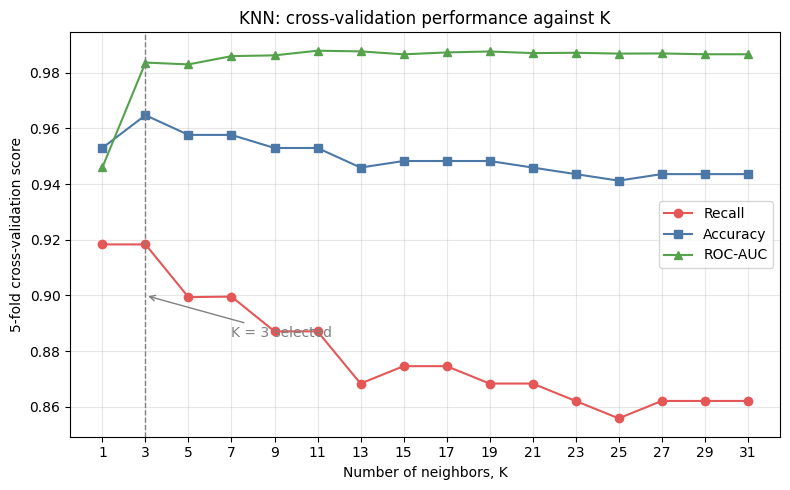

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_values, cv_recall, marker="o", label="Recall", color="#E45756")
ax.plot(k_values, cv_accuracy, marker="s", label="Accuracy", color="#4C78A8")
ax.plot(k_values, cv_auc, marker="^", label="ROC-AUC", color="#54A24B")
ax.axvline(3, linestyle="--", color="gray", linewidth=1)
ax.annotate("K = 3 selected", xy=(3, 0.90), xytext=(7, 0.885),
            arrowprops=dict(arrowstyle="->", color="gray"), color="gray")
ax.set_xlabel("Number of neighbors, K")
ax.set_ylabel("5-fold cross-validation score")
ax.set_title("KNN: cross-validation performance against K")
ax.set_xticks(k_values)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

#### Which K did I choose, and why?

**K = 3.**

K = 1 and K = 3 are tied on cross-validated recall, both at 0.918. But other metrics help to separate them decisively:

| K | CV Recall | CV Accuracy | CV ROC-AUC |
|---|---|---|---|
| 1 | 0.918 | 0.953 | 0.946 |
| 3 | 0.918 | **0.965** | **0.984** |

If K = 1, each data point classification depends entirely on its nearest neighbor since all points are classified based solely on that one point. This is the most variable option among the choices presented. The ROC-AUCs of 0.946 versus 0.984 illustrate the tradeoff involved: predictions generated by K = 1 give badly calibrated probabilities, since a prediction can be only a 0 or 1 with no in-betweens.

K = 3 matches K = 1 on our top metric, but with better stability and usable probabilities. Recall declines from K = 5 onward, so a larger K is unnecessary.

In [14]:
BEST_K = 3
knn = Pipeline([("scaler", StandardScaler()),
                ("model", KNeighborsClassifier(n_neighbors=BEST_K))])
knn.fit(X_train, y_train)
knn_probs = knn.predict_proba(X_test)[:, 1]
knn_preds = knn.predict(X_test)
print(f"Final KNN fitted with K = {BEST_K}.")

Final KNN fitted with K = 3.


### 3.4 Choosing among the four classifiers

The four models are compared here on the training data only, using the same five folds for each. This gives a basis for choosing a classifier that does not depend on the test set. The out-of-fold probabilities are kept, because the threshold analysis in Part 6 uses them.

In [15]:
# Five-fold cross-validation on the training data, same folds for every model.
cv_models = {
    "Logistic Regression": logreg,
    "LDA": lda,
    "QDA": qda,
    f"KNN, K={BEST_K}": knn,
}

cv_rows = []
oof_probs = {}
for name, model in cv_models.items():
    row = {"Model": name}
    for metric in ["accuracy", "precision", "recall", "roc_auc"]:
        row[metric] = cross_val_score(model, X_train, y_train, cv=cv, scoring=metric).mean()
    cv_rows.append(row)
    # Out-of-fold probabilities: every training row is scored by a model that never saw it.
    oof_probs[name] = cross_val_predict(model, X_train, y_train, cv=cv,
                                        method="predict_proba")[:, 1]

cv_table = pd.DataFrame(cv_rows).set_index("Model")
cv_table.columns = ["Accuracy", "Precision", "Recall", "ROC-AUC"]
print("Cross-validation on the training data, 5 folds\n")
print(cv_table.round(4).to_string())

Cross-validation on the training data, 5 folds

                     Accuracy  Precision  Recall  ROC-AUC
Model                                                    
Logistic Regression    0.9718     0.9810  0.9435   0.9914
LDA                    0.9530     0.9860  0.8867   0.9899
QDA                    0.9648     0.9759  0.9310   0.9889
KNN, K=3               0.9648     0.9871  0.9183   0.9837


Logistic regression is the strongest model on the training data. It has the highest cross-validated recall at 0.9435 and the highest ROC-AUC at 0.9914. LDA has the lowest recall at 0.8867, QDA reaches 0.9310 and KNN with K = 3 reaches 0.9183. All four have precision between 0.976 and 0.987, so the models differ mostly in how many cancers they miss, which is the error that matters most here. This is the basis for expecting logistic regression to be the model to deploy, and Part 6 checks that again after the thresholds are tuned.

### 3.5 Test predictions and probabilities

The table below holds the actual class, the predicted probability of malignancy and the predicted class at a threshold of 0.50 for all four models. It is also saved as `test_predictions.csv`.

In [16]:
# Actual class, predicted probability of malignancy, and predicted class at a threshold of 0.50.
test_predictions = pd.DataFrame({"actual": y_test.values}, index=y_test.index)
for short, probs, preds in [("logreg", logreg_probs, logreg_preds),
                            ("lda", lda_probs, lda_preds),
                            ("qda", qda_probs, qda_preds),
                            ("knn", knn_probs, knn_preds)]:
    test_predictions[f"{short}_prob"] = probs.round(4)
    test_predictions[f"{short}_class"] = preds

# In Colab this file is saved in the session folder, next to the uploaded files.
test_predictions.to_csv("test_predictions.csv", index_label="row")
print("Saved test_predictions.csv with", len(test_predictions), "rows")
test_predictions.head(10)

Saved test_predictions.csv with 143 rows


,actual,logreg_prob,logreg_class,lda_prob,lda_class,qda_prob,qda_class,knn_prob,knn_class
12,1,0.9994,1,0.5741,1,1.0000,1,1.0,1
506,0,0.0039,0,0.0002,0,0.0000,0,0.0,0
321,1,0.9997,1,0.9840,1,1.0000,1,1.0,1
71,0,0.0000,0,0.0000,0,0.0000,0,0.0,0
375,0,0.0345,0,0.0030,0,0.0150,0,0.0,0
362,0,0.0036,0,0.0001,0,0.0000,0,0.0,0
442,0,0.0004,0,0.0000,0,0.0000,0,0.0,0
125,0,0.0019,0,0.0002,0,0.0000,0,0.0,0
267,0,0.0069,0,0.0003,0,0.0000,0,0.0,0
347,0,0.0989,0,0.1230,0,0.0125,0,0.0,0


---
# Part 4: Evaluate the Models

All four models are now compared on the **test data**, which has not been touched.

### 4.1 Threshold selection

The following confusion matrices are based on a threshold of **0.50**. This is the default traditional value: a tumor is classified as malignant if the probability of it being malignant from the model exceeds 0.50.

Selecting 0.50 as the threshold is a deliberate choice for the beginning and not the solution itself. It considers a false positive and a false negative to be of equal importance, which Part 1 shows to be incorrect for cancer screening. Selecting 0.50 makes it possible to compare all four models under equal conditions, after which Part 6 chooses a better threshold from the training data alone, with the rule stated there.

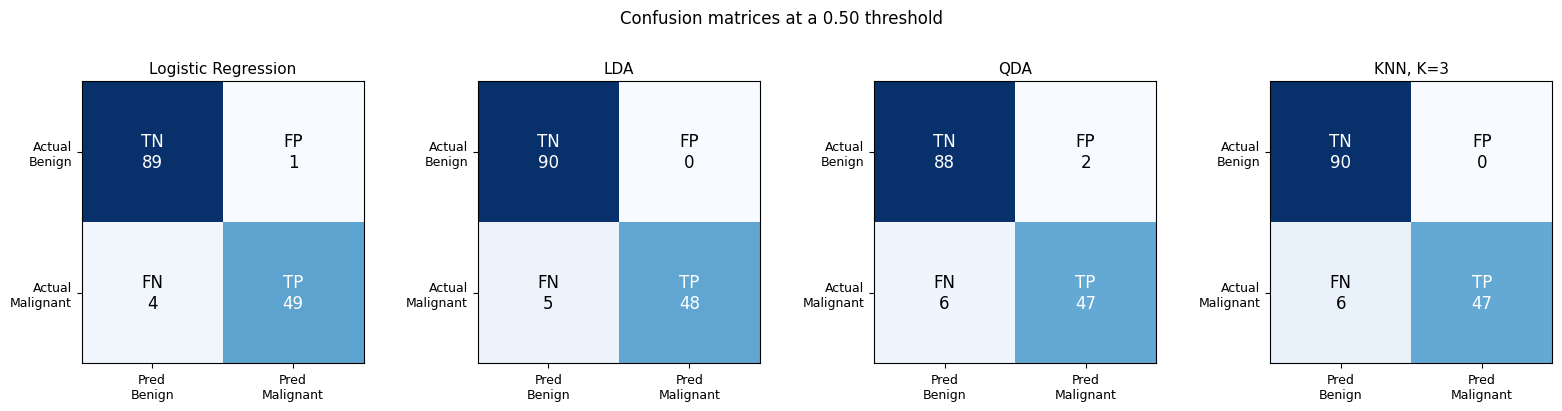

Logistic Regression     TN= 89  FP= 1  FN= 4  TP= 49   <- 4 missed cancers
LDA                     TN= 90  FP= 0  FN= 5  TP= 48   <- 5 missed cancers
QDA                     TN= 88  FP= 2  FN= 6  TP= 47   <- 6 missed cancers
KNN, K=3                TN= 90  FP= 0  FN= 6  TP= 47   <- 6 missed cancers


In [17]:
model_outputs = {
    "Logistic Regression": (logreg_preds, logreg_probs),
    "LDA": (lda_preds, lda_probs),
    "QDA": (qda_preds, qda_probs),
    f"KNN, K={BEST_K}": (knn_preds, knn_probs),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (name, (preds, probs)) in zip(axes, model_outputs.items()):
    cm = confusion_matrix(y_test, preds)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred\nBenign", "Pred\nMalignant"], fontsize=9)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual\nBenign", "Actual\nMalignant"], fontsize=9)
    labels = [["TN", "FP"], ["FN", "TP"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]}", ha="center", va="center",
                    fontsize=12, color="white" if cm[i, j] > cm.max()/2 else "black")
plt.suptitle("Confusion matrices at a 0.50 threshold", y=1.04)
plt.tight_layout(); plt.show()

for name, (preds, probs) in model_outputs.items():
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    print(f"{name:22s}  TN={tn:3d}  FP={fp:2d}  FN={fn:2d}  TP={tp:3d}   <- {fn} missed cancers")

In [18]:
rows = []
for name, (preds, probs) in model_outputs.items():
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "Specificity": tn / (tn + fp),
        "F1": f1_score(y_test, preds),
        "ROC-AUC": roc_auc_score(y_test, probs),
    })

results = pd.DataFrame(rows).set_index("Model")
print("Model comparison on the test set at a threshold of 0.50\n")
print(results.round(4).to_string())

Model comparison on the test set at a threshold of 0.50

                     Accuracy  Precision  Recall  Specificity      F1  ROC-AUC
Model                                                                         
Logistic Regression    0.9650     0.9800  0.9245       0.9889  0.9515   0.9962
LDA                    0.9650     1.0000  0.9057       1.0000  0.9505   0.9960
QDA                    0.9441     0.9592  0.8868       0.9778  0.9216   0.9945
KNN, K=3               0.9580     1.0000  0.8868       1.0000  0.9400   0.9881


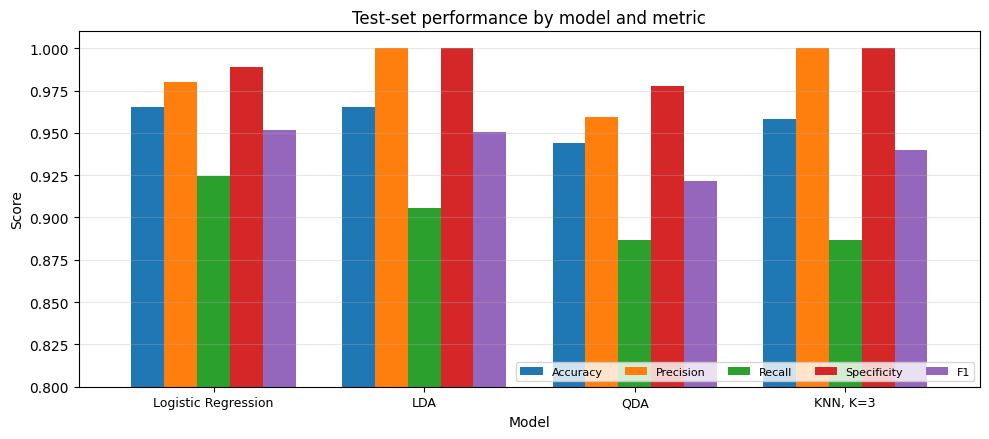

In [19]:
ax = results[["Accuracy", "Precision", "Recall", "Specificity", "F1"]].plot(
    kind="bar", figsize=(10, 4.5), width=0.78)
ax.set_ylim(0.80, 1.01)
ax.set_ylabel("Score")
ax.set_title("Test-set performance by model and metric")
ax.set_xticklabels(results.index, rotation=0, fontsize=9)
ax.legend(loc="lower right", ncol=5, fontsize=8)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

---
# Part 5: Reflect on the Results

### What the table shows

**Accuracy is equally high for Logistic Regression and LDA; they are both 96.5% accurate but reach the same result through different techniques.** Logistic Regression fails to diagnose 4 cancers and provides 1 false positive. LDA does not diagnose 5 cancers and provides no false positive cases. However, since we have the same level of accuracy, and from the clinical standpoint, the fact that with Logistic Regression one additional cancer is detected makes it a better choice in this case.

This example clearly demonstrates how accuracy is an inappropriate measure of performance.

**Both QDA and KNN cannot identify 6 cancers, yet these algorithms have drastically different behavior in other cases.** While QDA makes the greatest number of 2 false positives and is the largest in terms of all the models, the method has the worst performance. A likely explanation is that QDA estimates the covariance matrix for each class individually, which results in 930 estimated parameters for the sample of size 426, although this notebook does not test that.

On the contrary, KNN is the most conservative algorithm among four. It did not make any mistakes with the false positives, which means that the precision and specificity of KNN equal 1.000, while the accuracy of KNN is 95.8% and is greater than the accuracy of QDA. Yet, it missed 6 cancers.

### Which metrics are informative here

In turn, the first part demonstrated that the cost of false negatives is substantially higher compared to the cost of false positives. Therefore, we get our answers regarding the order of metrics:

Firstly, **Recall** metric needs to be taken into account. It measures the ratio of truly malignant masses among all really malignant detected by the algorithm. From the results presented above, it can be seen that the best recall metric was attained through logistic regression equal to 0.925.

Second, the ROC-AUC is a very important measure, because it demonstrates the ability of the model to rank the malignant masses above benign masses regardless of the chosen threshold. This is crucial, since according to the 6th section, we will no longer use the 0.50 threshold.

**The specificity and precision must be considered, although not the decisive ones.** They cover the false alarm cost, which is correct, although it can be balanced out.

**The least informative measures are accuracy and F1-score.** Neither of the measures discriminates between the types of errors. The F1-score is the harmonic mean of the precision and recall, meaning that they are treated as equally significant, which is not correct.

---
# Part 6: ROC Curves and Threshold Analysis

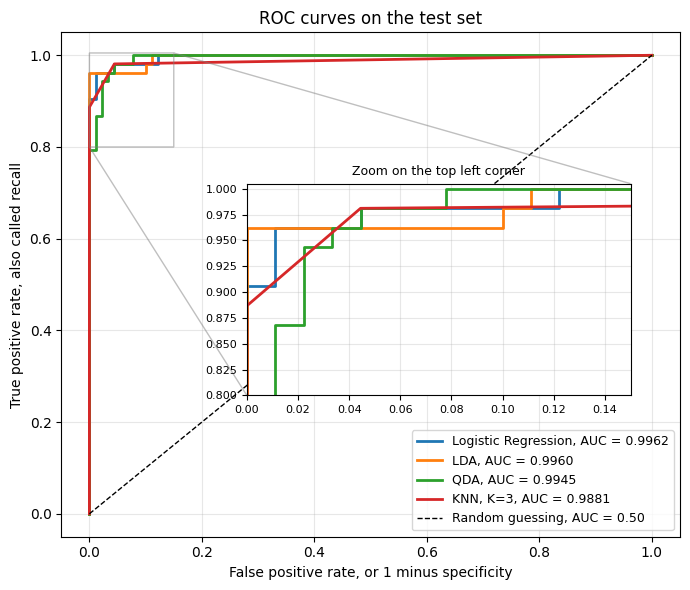

ROC-AUC by model:
  Logistic Regression    0.9962
  LDA                    0.9960
  QDA                    0.9945
  KNN, K=3               0.9881


In [20]:
fig, ax = plt.subplots(figsize=(7, 6))
axins = ax.inset_axes([0.30, 0.28, 0.62, 0.42])
for name, (preds, probs) in model_outputs.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax.plot(fpr, tpr, linewidth=2, label=f"{name}, AUC = {roc_auc_score(y_test, probs):.4f}")
    axins.plot(fpr, tpr, linewidth=2)
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random guessing, AUC = 0.50")
axins.set_xlim(0, 0.15)
axins.set_ylim(0.80, 1.005)
axins.grid(alpha=0.3)
axins.tick_params(labelsize=8)
axins.set_title("Zoom on the top left corner", fontsize=9)
ax.indicate_inset_zoom(axins, edgecolor="gray")
ax.set_xlabel("False positive rate, or 1 minus specificity")
ax.set_ylabel("True positive rate, also called recall")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig("roc_curves.png", dpi=200, bbox_inches="tight")
plt.show()

print("ROC-AUC by model:")
for name, (preds, probs) in model_outputs.items():
    print(f"  {name:22s} {roc_auc_score(y_test, probs):.4f}")

### What ROC-AUC tells us, in plain terms

This small chart in the figure focuses on the top-left region, where the four curves appear to be very close together.

In the ROC graph, the trade-off between cancers caught and false positives for varying decision thresholds is evaluated. Every point on the chart represents one particular threshold value.

**The AUC of the ROC refers to the area under the ROC, and the AUC can be interpreted as follows: if randomly selected an example of a malignant mass and a benign mass, then the AUC refers to the probability of the assignment of higher malignancy score to the first mass.**

The AUC of Logistic Regression is 0.9962; therefore, if randomly selected an example of a malignant and benign mass, Logistic Regression will rank the masses correctly in 99.6% of the cases.

It is important since **the AUC score is threshold-independent**. In contrast to accuracy, precision, and recall, all of which evaluate the quality of classification on one particular threshold value, AUC evaluates how well the ranking is performed. Therefore, AUC will help understand whether the classifier has really learned to rank or it works just fine on 0.50 threshold value by pure luck.

In case with KNN analysis, it is easy to see. KNN accuracy equals 95.8% and is the third-highest among the four classifiers while its AUC equals 0.9881 and is the lowest. The reason is quite obvious from the KNN ROC curve plot, which is more angular than the ROC curves of the other three models. For instance, for K = 3, the probability predicted by KNN model can have only 4 possible values, namely 0, 0.33, 0.67, or 1.

In [21]:
# Threshold table built from the TRAINING data only.
# These are the out-of-fold probabilities from section 3.4. Every training row is scored by a
# model that never saw that row, so thresholds can be examined without the test set.
logreg_oof_probs = oof_probs["Logistic Regression"]

print("Logistic regression at different thresholds, scored on the training data with 5-fold out-of-fold predictions\n")
print(f"{'Threshold':>10} {'FN':>4} {'FP':>4} {'Recall':>9} {'Precision':>10} {'Specificity':>12}")
print("-" * 56)
for t in [0.60, 0.50, 0.40, 0.30, 0.20, 0.10]:
    preds_t = (logreg_oof_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, preds_t).ravel()
    print(f"{t:>10.2f} {fn:>4d} {fp:>4d} {recall_score(y_train, preds_t):>9.4f} "
          f"{precision_score(y_train, preds_t):>10.4f} {tn/(tn+fp):>12.4f}")

Logistic regression at different thresholds, scored on the training data with 5-fold out-of-fold predictions

 Threshold   FN   FP    Recall  Precision  Specificity
--------------------------------------------------------
      0.60   11    1    0.9308     0.9933       0.9963
      0.50    9    3    0.9434     0.9804       0.9888
      0.40    7    6    0.9560     0.9620       0.9775
      0.30    4    8    0.9748     0.9509       0.9700
      0.20    4   13    0.9748     0.9226       0.9513
      0.10    4   25    0.9748     0.8611       0.9064


### Reading the threshold table

The table above uses only the training dataset: each training mass is classified by a model that has not been exposed to it, by means of 5-fold cross-validation, and hence there is no test result here.

**Reducing the threshold lowers misses but increases false alarms.** By going from 0.50 to 0.30, the number of misses reduces from 9 to 4 in case of the 159 malignant masses, while the number of false alarms increases from 3 to 8 in case of the 267 benign masses. At thresholds lower than 0.30, the number of misses does not reduce anymore and is 4 both at 0.20 and 0.10, while the number of false alarms increases further to 13 and 25.

All that changes between rows is the decision rule. There is no refitting of the model, whose coefficients remain the same. It is up to clinicians to decide how many false alarms can be tolerated per each miss.

### Determining the threshold

Only training data is used to determine the threshold, and it is determined based on the out-of-fold probabilities discussed in section 3.4. For each model, the list of potential thresholds begins from 0.05 to 0.95 with an increment of 0.05. The selected threshold is the maximum value among the thresholds where out-of-fold recall is at least 0.95. A recall target of 0.95 is set based on the cost of missing a cancer case, since it means about one cancer is missed in twenty cases. For models which do not meet the threshold, the threshold is the maximum one where the recall is the highest.

A similar criterion is followed in the determination of the best classifier. It is the classifier with the least number of false positives among the classifiers meeting the recall target.

In [22]:
THRESHOLD_GRID = np.round(np.arange(0.05, 0.951, 0.05), 2)
RECALL_TARGET = 0.95

def oof_counts(probs, threshold):
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, preds).ravel()
    return tn, fp, fn, tp

def choose_threshold(probs):
    rows = []
    for t in THRESHOLD_GRID:
        tn, fp, fn, tp = oof_counts(probs, t)
        rows.append((t, tp / (tp + fn)))
    reaching = [t for t, rec in rows if rec >= RECALL_TARGET]
    if reaching:
        return max(reaching), True
    best_recall = max(rec for t, rec in rows)
    return max(t for t, rec in rows if rec == best_recall), False

tuned_thresholds = {}
selection_rows = []
for name, probs in oof_probs.items():
    t, reached = choose_threshold(probs)
    tn, fp, fn, tp = oof_counts(probs, t)
    tuned_thresholds[name] = t
    selection_rows.append({"Model": name, "Threshold": t, "Reached target": reached,
                           "Missed cancers": fn, "False alarms": fp,
                           "Recall": tp / (tp + fn), "Specificity": tn / (tn + fp)})

selection_table = pd.DataFrame(selection_rows).set_index("Model")
print("Threshold chosen for each model on the training data\n")
print(selection_table.round(4).to_string())

reached_models = selection_table[selection_table["Reached target"]]
if len(reached_models) > 0:
    pool = reached_models.join(cv_table["ROC-AUC"])
    pool = pool.sort_values(["False alarms", "ROC-AUC"], ascending=[True, False])
else:
    pool = selection_table.sort_values("Recall", ascending=False)

SELECTED_MODEL = pool.index[0]
SELECTED_THRESHOLD = float(tuned_thresholds[SELECTED_MODEL])
print(f"\nSelected model:     {SELECTED_MODEL}")
print(f"Selected threshold: {SELECTED_THRESHOLD:.2f}")

Threshold chosen for each model on the training data

                     Threshold  Reached target  Missed cancers  False alarms  Recall  Specificity
Model                                                                                            
Logistic Regression       0.40            True               7             6  0.9560       0.9775
LDA                       0.05            True               6            12  0.9623       0.9551
QDA                       0.10           False               9             6  0.9434       0.9775
KNN, K=3                  0.30            True               4            20  0.9748       0.9251

Selected model:     Logistic Regression
Selected threshold: 0.40


Logistic regression, LDA, and KNN have achieved the recall objective of 0.95, but QDA does not. The maximum out-of-fold recall for QDA is 0.9434 with a threshold of 0.10.

The thresholds vary quite much. For logistic regression, 0.40 threshold suffices, with 7 false negatives and 6 false positives in the training set. For LDA, it is 0.05 threshold, and it incurs 12 false positives, whereas for KNN it is 0.30 threshold, and this incurs 20 false positives. For KNN with K = 3, 0.30 threshold indicates that one malignant mass out of three will be sufficient to classify a mass as malignant. Hence logistic regression has the least number of false positives amongst the models that achieve the recall objective, and so it is chosen at a threshold of 0.40.

### The chosen thresholds on the test set

Each model is now scored on the test set once, at the threshold chosen for it above. The columns for 0.50 repeat the earlier results, so the effect of the threshold is visible.

In [23]:
# Test-set results for each model at the threshold chosen on the training data.
rows = []
for name, (preds, probs) in model_outputs.items():
    t = tuned_thresholds[name]
    tuned_preds = (probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, tuned_preds).ravel()
    tn5, fp5, fn5, tp5 = confusion_matrix(y_test, preds).ravel()
    rows.append({"Model": name, "Threshold": t,
                 "Missed at 0.50": fn5, "Missed at tuned": fn,
                 "False alarms at 0.50": fp5, "False alarms at tuned": fp,
                 "Recall": recall_score(y_test, tuned_preds),
                 "Precision": precision_score(y_test, tuned_preds),
                 "Specificity": tn / (tn + fp),
                 "F1": f1_score(y_test, tuned_preds)})

tuned_results = pd.DataFrame(rows).set_index("Model")
print("Test set at the threshold chosen for each model on the training data\n")
print(tuned_results.round(4).to_string())

Test set at the threshold chosen for each model on the training data

                     Threshold  Missed at 0.50  Missed at tuned  False alarms at 0.50  False alarms at tuned  Recall  Precision  Specificity      F1
Model                                                                                                                                               
Logistic Regression       0.40               4                3                     1                      1  0.9434     0.9804       0.9889  0.9615
LDA                       0.05               5                2                     0                      9  0.9623     0.8500       0.9000  0.9027
QDA                       0.10               6                4                     2                      2  0.9245     0.9608       0.9778  0.9423
KNN, K=3                  0.30               6                1                     0                      4  0.9811     0.9286       0.9556  0.9541


Logistic regression at selected thresholds on training data misses 3 out of 53 cancers and generates 1 false positive, achieving recall = 0.9434 and specificity = 0.9889. Shifting its threshold from 0.50 to 0.40 helps capture 1 more cancer without generating any false positives.

On the other hand, these methods find the extra cancers by giving more false positives. In particular, KNN misses one case and generates 4 false positives, and LDA misses two cases and generates 9. QDA, which does not meet the requirement even once, misses 4 cases and generates 2 false positives, hence doing worse than logistic regression on both accounts. It is not possible to put any weight on a missed cancer relative to a false positive without knowing how much worse a missed cancer is, and this is not available in the data. There are two reasons why I am reluctant to go with KNN based on this table. First, the classifier was selected using the training set, and changing it after looking at the test set would go against that. Second, KNN with K = 3 has only four probabilities, hence the threshold is a crude switch rather than a dial, and it has the most false positives at its selected threshold, 20 as opposed to 6 for logistic regression.

---
# Part 7: Final Analysis

### 7.1 How the four classifiers compare

They all work well. The least effective classifier correctly assigns classification to 94% of all masses, meaning that this is not the issue where one algorithm succeeds and others fail. The difference between them is in **what they make a mistake about**.

**When applying the default threshold, logistic regression is capable of detecting the most number of cancers.** It misclassifies 4 of 53 cancers among 143 test masses.

**The only difference between LDA and this model is that LDA is more cautious.** In other words, LDA does not report any false positives but misses five cases of cancer rather than four. Both models have the same 96.5% of accuracy, which is the best possible illustration of why accuracy is not very useful metric.

**There were six cancers missed by QDA and KNN.** The reason for QDA being the worst among all models was that it provided the highest amount of false positives. This model is more flexible than LDA; therefore, it needs a larger number of parameters which cannot be estimated accurately because there are only 426 samples in the training set. On the other hand, KNN was the most conservative model since it did not make any mistakes while working with benign masses but missed two cancers in comparison to logistic regression.

Logistic Regression, LDA and QDA give a higher AUC score above 0.994 by estimating probability. While KNN model has a higher accuracy rate, it gives a score of 0.988 in AUC value. KNN with 3 nearest neighbors can provide only four probability values: 0, 0.33, 0.67, and 1.

**Tuning the threshold makes a big difference.** Logistic regression does not detect 3 cancers and generates 1 false alarm, KNN fails to detect 1 cancer and generates 4 false alarms, LDA misses 2 and generates 9 false alarms, and QDA fails to detect 4 and generates 2 false alarms. QDA is worse than logistic regression in all these aspects.

### 7.2 Which model I would deploy

**Logistic Regression, where the decision cutoff was set to 0.40 rather than 0.50.**

I selected it based on the training data, prior to seeing the testing results. This model offers the best cross-validated recall value, which is 0.9435, and the best cross-validated ROC-AUC value, which is 0.9914, and it produced the least number of false positives amongst all models that achieved the recall target. The recall is my main concern due to the nature of the problem.

It ranks malignant masses above benign ones with a ROC-AUC of 0.9962 for the test dataset. In turn, LDA scores almost the same result with a ROC-AUC of 0.9960, therefore AUC does not distinguish between these models. Since logistic regression gives a probability, it is possible to change the threshold. Threshold 0.40 was determined using training data. For the test sample, 3 out of 53 tumors are missed and 1 false positive is predicted at threshold 0.40 in comparison with 4 missed and 1 false positive at threshold 0.50; there is a difference of one patient only. Four thresholds are available for KNN when K=3 because of limited number of probabilities.

The model is interpretable. Each feature has a coefficient with a sign and magnitude, so a physician is able to understand the importance of features. Taking into account strong correlation between predictors, the coefficients must be examined together rather than separately.

It must be stated that this decision is not an easy one to make. At their respective cutoffs, KNN has one missed cancer and LDA has two missed cancers, compared to three for the logistic regression model. They also have four and nine false alarms, compared to just one by the logistic regression. This means that, if missed cancer is regarded as much more serious than false alarms, one of these could be used.

### 7.3 One limitation

**The test set includes only 53 malignant tumors.**

All of the previously presented recall values depend on this value. The gap between the logistic regression and LDA values, 0.925 and 0.906 respectively,  equals only one person. If one person was in another group, the ranking of the algorithms would be different. At the selected thresholds, there is also just a difference of a few people.

It does not seem like enough evidence to prove superiority of one algorithm over another. The general statement is true: the data contains much information and all of the four algorithms use it; however, the ranking of the algorithms cannot be proven with 143 test instances.

One more limitation is the single-source nature of the data and the standard processing method for the images. There has been no confirmation of the model's efficacy on images created by other devices and laboratories.

### 7.4 What I would want before real-world use

**Much bigger and more diverse validation sample** from hospitals using diverse imaging technologies and patients who resemble those in the environment where the model will operate. Performance on data from one hospital says very little about performance on data from other hospitals.

**The cost ratio of the two errors.** Everything in favor of a certain threshold hinges on the fact that false negatives are costlier than false positives – this is an obvious truth in the general sense of things. The recall requirement of 0.95 for the selected threshold is a subjective choice on my part and is not based on any calculations. It can be quantified by medical and health economists.

**Information about outcomes for patients, not just the diseases that they have been diagnosed with.** It’s a lot more useful to have an algorithm which can detect aggressive cancers at an early stage than a system that can detect a lot of non-aggressive cancers with the same recall rate.

**Confirmation that the predictor values can be reused.** These thirty variables come from a specific image analysis workflow. In case someone calculates these variables using a different method somewhere else, the whole system is not reusable anymore.

In [24]:
# The selected model and threshold come from the training cross-validation in Part 6.
selected_probs = model_outputs[SELECTED_MODEL][1]

print("=" * 68)
print("SUMMARY")
print("=" * 68)
print(results.round(4).to_string())
print()
print(f"Selected model:     {SELECTED_MODEL}")
print(f"Selected threshold: {SELECTED_THRESHOLD:.2f}")
preds_final = (selected_probs >= SELECTED_THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, preds_final).ravel()
print(f"\nAt the selected threshold of {SELECTED_THRESHOLD:.2f} on {len(y_test)} test masses:")
print(f"  Cancers caught:  {tp} of {tp+fn}")
print(f"  Cancers missed:  {fn}")
print(f"  False alarms:    {fp}")
print(f"  Recall:          {recall_score(y_test, preds_final):.4f}")
print(f"  Specificity:     {tn/(tn+fp):.4f}")

SUMMARY
                     Accuracy  Precision  Recall  Specificity      F1  ROC-AUC
Model                                                                         
Logistic Regression    0.9650     0.9800  0.9245       0.9889  0.9515   0.9962
LDA                    0.9650     1.0000  0.9057       1.0000  0.9505   0.9960
QDA                    0.9441     0.9592  0.8868       0.9778  0.9216   0.9945
KNN, K=3               0.9580     1.0000  0.8868       1.0000  0.9400   0.9881

Selected model:     Logistic Regression
Selected threshold: 0.40

At the selected threshold of 0.40 on 143 test masses:
  Cancers caught:  50 of 53
  Cancers missed:  3
  False alarms:    1
  Recall:          0.9434
  Specificity:     0.9889
